# One neuron under current
Give two Izhikevich cells the same current pulse. Watch how recovery changes the interval between spikes. These are the same two cell types used in the Pong network.

$$\frac{dv}{dt}=0.04v^2+5v+140-u+I,\qquad \frac{du}{dt}=a(bv-u).$$

Here $v$ is membrane voltage in millivolts, $u$ is recovery, and $I$ is input in model units. At $v\geq 30$ mV the cell emits a spike, resets $v$ to $c$, and adds $d$ to $u$. Both cell types use $b=0.2$ and $c=-65$. For the regular-spiking cell, $(a,d)=(0.02,8)$; for the fast-spiking cell, $(a,d)=(0.1,2)$.

[Izhikevich, *Simple Model of Spiking Neurons* (2003)](https://izhikevich.org/publications/spikes.htm)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from model import IzhikevichPopulation

cells = IzhikevichPopulation(size=2, n_excitatory=1)
time = np.arange(250)
current = np.where((time >= 35) & (time < 210), 10.0, 0.0)
voltage, recovery, spikes = [], [], []
for drive in current:
    fired = cells.step(drive)
    spikes.append(fired)
    voltage.append(cells.v.copy())
    recovery.append(cells.u.copy())
spikes = np.asarray(spikes)
# The solver has already reset a firing cell. Mark its event at threshold for display.
display_voltage = np.where(spikes, 30.0, voltage)

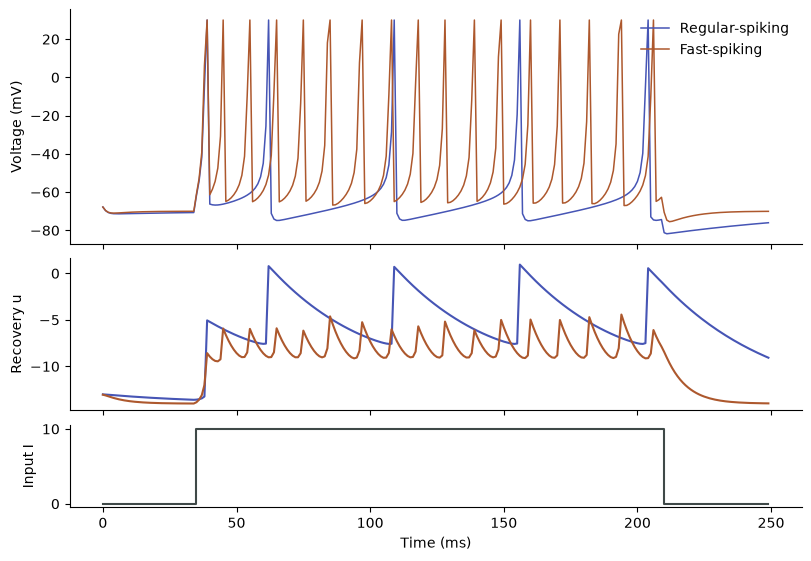

Spikes during the trial (regular, fast): [5, 17]


In [2]:
fig, axes = plt.subplots(3, 1, figsize=(8, 5.5), sharex=True, layout='constrained',
                         height_ratios=[2, 1.3, 0.7])
for cell, (name, color) in enumerate([('Regular-spiking', '#4655b5'), ('Fast-spiking', '#ad582d')]):
    axes[0].plot(time, display_voltage[:, cell], color=color, linewidth=1.1, label=name)
    axes[1].plot(time, np.asarray(recovery)[:, cell], color=color)
axes[0].set_ylabel('Voltage (mV)')
axes[0].legend(frameon=False, loc='upper right')
axes[1].set_ylabel('Recovery u')
axes[2].step(time, current, where='post', color='#3f4948')
axes[2].set(xlabel='Time (ms)', ylabel='Input I')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()
print('Spikes during the trial (regular, fast):', spikes.sum(axis=0).tolist())

**Try it.** Raise the pulse amplitude from 10 to 14 model units and rerun the notebook. Compare the spike counts and the spacing of the first and last spikes. The cell parameters stay fixed throughout this experiment.